# Covariate Ablation

Extracted from `energy_scores_by_distance_group.ipynb`.


In [1]:
from pathlib import Path
import csv
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from movebench import paths
import movebench.bench.run as bench_run
import movebench.bench.run_state as bench_run_state
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    TIME_COL,
    haversine_distance_m,
    load_trajectories_csv,
)

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_rows", 200)


In [2]:
RUNS_ROOT = paths.repo_root() / "results" / "bench" / "runs"
STUDIES_V2_PATH = paths.repo_root() / "MoveBench Studies V2.csv"
TRAITS_PATH = paths.repo_root().parent / "movebench-figures" / "outputs" / "traits" / "movebench_traits.csv"

PLOT_METHODS = [
    "baseline_randomwalk",
    "issf_linear",
    "issf_mlp",
    "deepssf",
    "moveformer",
]
NORMALIZE_BY = "baseline_nomove"
REQUIRED_METHODS = [NORMALIZE_BY, *PLOT_METHODS]
TIMESCALE_ORDER = ["1h", "12h", "1d", "7d"]
SPLIT_KEY = "test_temporal"
INDIVIDUAL_SPLIT_KEY = "test_individual"

SHORT_KM = 25.0
LONG_KM = 650.0

STUDY_ID_OVERRIDES = {
    ("Antarctic Petrel", "Thalassoica antarctica"): "klappstein2024_smoothSSF_data_petrel",
    ("Fiedler_0a3ec70a; Fiedler_520a64ae; Fiedler_5f8c5199", "Ciconia ciconia"): "Fiedler_lifetrack_stork_all",
    ("Klzsch_22d42221; Klzsch_2e9dace9", "Anser albifrons"): "Klzsch_22d42221_2e9dace9_all",
    ("AMT Deer", "Cervus elaphus"): "amtdeer_wgs84",
    ("Alaska Sea Lion", "Eumetopias jubatus"): "wilson2018_sea_lion_telemetry",
    ("Australia water buffalo", "Bubalus bubalis"): "forrest2024_buffalo",
    ("Botswana Hyena", "Crocuta crocuta"): "cazzi2016_hyena",
    ("Colorado Mountain Lion", "Puma concolor"): "hooten2018_mountain_lion_AM80",
    ("Desert Pronghorn", "Antilocapra americana"): "aikens2025_pronghorn",
    ("Elephant seal", "Mirounga angustirostris"): "costa2024_elephant_seals",
    ("Illinois Deer", "Odocoileus virginianus"): "egan2025_deer",
    ("Kenya Wildebeast", "Connochaetes taurinus"): "stabach2020_wildebeest",
    ("Mississippi Pig", "Sus scrofa"): "potts2022_pig",
    ("Mountain Pronghorn", "Antilocapra americana"): "aikens2024_pronghorn",
    ("Namibia Elephants", "Loxodonta africana"): "killian_elephants",
    ("Tsavo Lions", "Panthera leo"): "tsavo_lions",
}

PANEL_ORDER = [
    "bird_short_medium",
    "bird_long",
    "mammal_short",
    "mammal_medium_long",
    "marine_all",
    "reptiles_all",
]
PANEL_TITLES = {
    "bird_short_medium": "Bird < 650km ",
    "bird_long": "Bird > 650km",
    "reptiles_all": "Terrestrial Reptile",
    "mammal_short": "Mammal < 25km",
    "mammal_medium_long": "Mammal > 25km",
    "marine_all": "Marine",
}
METHOD_COLORS = {
    "baseline_randomwalk": "#363636",
    "issf_linear": "#c1121f",
    "issf_mlp": "#f77f00",
    "deepssf": "#003049",
    "moveformer": "#669bbc",
}
COVARIATE_COMPARISON_METHODS = ["issf_linear", "issf_mlp", "deepssf", "moveformer"]
EXPERIMENTAL_COVARIATE_COMPARISON_METHODS = ["issf_linear_time", "issf_mlp_time"]
ALL_COVARIATE_COMPARISON_METHODS = [
    *COVARIATE_COMPARISON_METHODS,
    *EXPERIMENTAL_COVARIATE_COMPARISON_METHODS,
]
CORE_COVARIATE_COMPARISON_EXPERIMENTS = ["main_results", "covariate_comparison", "alphaearth_and_marine_mini"]
EXPERIMENTAL_COVARIATE_COMPARISON_EXPERIMENTS = ["covariate_comparison_time"]
COVARIATE_SET_ORDER = ["lite", "all_environmental", "alphaearth_only", "alphaearth_and_marine", "all"]
COVARIATE_COLORS = {
    "lite": "#ADCFFF",
    "all_environmental": "#3a8cff",
    "alphaearth_only": "#288077",
    "alphaearth_and_marine": "#1b9aaa",
    "all": "#00409a",
}
TRUE_MAIN_EXPERIMENT_NAMES = ["main_results_v2"]
BASELINE_EXPERIMENT_NAMES = ["main_results"]
BASELINE_METHODS = [NORMALIZE_BY, "baseline_randomwalk"]
MAIN_METHODS = [method for method in REQUIRED_METHODS if method not in BASELINE_METHODS]
_planned_run_map_cache: dict[tuple[tuple[str, ...], tuple[str, ...] | None], dict[str, dict[str, object]]] = {}
_completed_planned_runs_cache: dict[tuple[tuple[str, ...], tuple[str, ...] | None], dict[str, dict[str, object]]] = {}
_completed_run_inventory_cache: dict[tuple[object, ...], pd.DataFrame] = {}

print(f"Runs root: {RUNS_ROOT}")
print(f"Studies V2 CSV: {STUDIES_V2_PATH}")
print(f"Traits CSV: {TRAITS_PATH}")


def _study_ids_cache_key(study_ids: list[str] | None) -> tuple[str, ...] | None:
    if study_ids is None:
        return None
    return tuple(str(study_id) for study_id in study_ids)


def _experiment_cache_key(
    *experiment_names: str,
    study_ids: list[str] | None = None,
) -> tuple[tuple[str, ...], tuple[str, ...] | None]:
    return tuple(str(name) for name in experiment_names), _study_ids_cache_key(study_ids)


def planned_run_map(*experiment_names: str, study_ids: list[str] | None = None) -> dict[str, dict[str, object]]:
    cache_key = _experiment_cache_key(*experiment_names, study_ids=study_ids)
    cached_runs = _planned_run_map_cache.get(cache_key)
    if cached_runs is not None:
        return cached_runs

    wanted_studies = None if study_ids is None else {str(study_id) for study_id in study_ids}
    selected_experiments = {str(name) for name in experiment_names}
    planned_runs: dict[str, dict[str, object]] = {}
    readiness_map: dict[str, dict[str, object]] = {}

    for module_path in bench_run.checked_in_experiment_module_paths():
        experiment = bench_run.load_experiment(module_path)
        if str(experiment.get("name", "")) not in selected_experiments:
            continue
        for run in bench_run.expand_experiment(
            experiment,
            readiness_map=readiness_map,
        ):
            run_payload = dict(run)
            study_id = str(run_payload.get("study_id", ""))
            if wanted_studies is not None and study_id not in wanted_studies:
                continue
            planned_runs[str(run_payload["run_key"])] = run_payload

    _planned_run_map_cache[cache_key] = planned_runs
    return planned_runs


def completed_planned_runs(*experiment_names: str, study_ids: list[str] | None = None) -> dict[str, dict[str, object]]:
    cache_key = _experiment_cache_key(*experiment_names, study_ids=study_ids)
    cached_runs = _completed_planned_runs_cache.get(cache_key)
    if cached_runs is not None:
        return cached_runs

    planned_runs = planned_run_map(*experiment_names, study_ids=study_ids)
    latest_run_records = bench_run_state.search_latest_run_records_by_key(list(planned_runs.keys()))
    completed_runs: dict[str, dict[str, object]] = {}

    for run_key, run_payload in planned_runs.items():
        latest_run = dict(latest_run_records.get(run_key, {}))
        if str(latest_run.get("status", "")) != "completed":
            continue
        completed_runs[run_key] = {
            "run_payload": run_payload,
            "latest_run": latest_run,
        }

    _completed_planned_runs_cache[cache_key] = completed_runs
    return completed_runs


def completed_main_and_baseline_runs(*, study_ids: list[str] | None = None) -> dict[str, dict[str, object]]:
    completed_runs: dict[str, dict[str, object]] = {}

    for run_key, payload in completed_planned_runs(*TRUE_MAIN_EXPERIMENT_NAMES, study_ids=study_ids).items():
        run_payload = dict(payload["run_payload"])
        if str(run_payload.get("method", "")) not in MAIN_METHODS:
            continue
        completed_runs[run_key] = payload

    for run_key, payload in completed_planned_runs(*BASELINE_EXPERIMENT_NAMES, study_ids=study_ids).items():
        run_payload = dict(payload["run_payload"])
        if str(run_payload.get("method", "")) not in BASELINE_METHODS:
            continue
        if str(run_payload.get("covariate_set", "")) != "all":
            continue
        completed_runs[run_key] = payload

    return completed_runs


def completed_run_inventory(
    *experiment_names: str,
    study_ids: list[str] | None = None,
    split_key: str = SPLIT_KEY,
) -> pd.DataFrame:
    cache_key = (*_experiment_cache_key(*experiment_names, study_ids=study_ids), str(split_key))
    cached_inventory = _completed_run_inventory_cache.get(cache_key)
    if cached_inventory is not None:
        return cached_inventory

    rows: list[dict[str, object]] = []
    for experiment_name in experiment_names:
        for run_key, payload in completed_planned_runs(experiment_name, study_ids=study_ids).items():
            run_payload = dict(payload["run_payload"])
            latest_run = dict(payload["latest_run"])
            study_id = str(run_payload.get("study_id", ""))
            timescale = str(run_payload.get("timescale", ""))
            method = str(run_payload.get("method", ""))
            covariate_set = str(run_payload.get("covariate_set", ""))

            if timescale not in TIMESCALE_ORDER:
                continue

            run_dir = RUNS_ROOT / run_key
            resolved_path = run_dir / "resolved_run.json"
            summary_path = run_dir / "final_metrics" / str(split_key) / "summary.json"
            if not summary_path.exists():
                continue

            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            if summary.get("energy_score") is None:
                continue

            rows.append(
                {
                    "experiment_name": str(experiment_name),
                    "run_dir": str(run_dir),
                    "run_key": run_key,
                    "study_id": study_id,
                    "timescale": timescale,
                    "covariate_set": covariate_set,
                    "method": method,
                    "completed_at": completed_at_for_run(latest_run, [resolved_path, summary_path]),
                    "energy_score": float(summary["energy_score"]),
                }
            )

    inventory_df = pd.DataFrame.from_records(
        rows,
        columns=[
            "experiment_name",
            "run_dir",
            "run_key",
            "study_id",
            "timescale",
            "covariate_set",
            "method",
            "completed_at",
            "energy_score",
        ],
    )
    _completed_run_inventory_cache[cache_key] = inventory_df
    return inventory_df


def completed_at_for_run(latest_run: dict[str, object], artifact_paths: list[Path]) -> float:
    end_time = latest_run.get("end_time")
    if isinstance(end_time, (int, float)):
        return float(end_time) / 1000.0
    return float(max(path.stat().st_mtime for path in artifact_paths))


Runs root: /data/vision/beery/scratch/justin/movebench/results/bench/runs
Studies V2 CSV: /data/vision/beery/scratch/justin/movebench/MoveBench Studies V2.csv
Traits CSV: /data/vision/beery/scratch/justin/movebench-figures/outputs/traits/movebench_traits.csv


In [3]:
def _method_label(method_key: str) -> str:
    return str(method_key).replace("baseline","").replace("_", " ").replace("randomwalk", "crw")

In [4]:


DETAIL_GROUP_OVERRIDES = {
    ("Setyawan_0425c92c", "Mobula"): "Marine Sharks and Rays",
    ("Botswana Hyena", "Crocuta crocuta"): "Terrestrial Mammals",
}


def load_group_lookup(traits_path: Path) -> dict[str, str]:
    group_lookup: dict[str, str] = {}
    with traits_path.open(newline="") as f:
        for row in csv.DictReader(f):
            group = row["group"].strip()
            if not group:
                continue

            corrected = row["study_species"].strip()
            original = row["study_species_original"].strip()

            if corrected:
                group_lookup[corrected] = group
            if original:
                group_lookup[original] = group

    for species, group in list(group_lookup.items()):
        if group == "Mammals":
            group_lookup[species] = "Terrestrial Mammals"

    group_lookup["Bubalus bubalis"] = "Freshwater Mammals"
    group_lookup["Mobula"] = "Marine Sharks and Rays"
    return group_lookup


def collapse_high_level_group(detail_group: str | float | None) -> str | None:
    if not isinstance(detail_group, str) or not detail_group:
        return None
    if detail_group.startswith("Marine"):
        return "Marine"
    if "Bird" in detail_group:
        return "Birds"
    if "Mammal" in detail_group:
        return "Terrestrial mammals"
    if "Reptile" in detail_group:
        return "Reptiles"
    return None


def classify_distance_bin(distance_km: float) -> str:
    if float(distance_km) < SHORT_KM:
        return "short"
    if float(distance_km) < LONG_KM:
        return "medium"
    return "long"


def assign_panel(high_level_group: str, distance_bin: str) -> str | None:
    if high_level_group == "Birds":
        return "bird_short_medium" if distance_bin in {"short", "medium"} else "bird_long"
    if high_level_group == "Reptiles":
        return "reptiles_all"
    if high_level_group == "Terrestrial mammals":
        return "mammal_short" if distance_bin == "short" else "mammal_medium_long"
    if high_level_group == "Marine":
        return "marine_all"
    return None


def _species_suffix(study_species: str) -> str:
    return str(study_species).strip().replace(" ", "_")


def _resolve_study_id(study_name: str, study_species: str, available_study_ids: set[str]) -> str | None:
    override = STUDY_ID_OVERRIDES.get((study_name, study_species))
    if override:
        return override
    if study_name in available_study_ids:
        return study_name

    prefix_matches = [
        study_id
        for study_id in available_study_ids
        if study_id.startswith(f"{study_name}_") or study_id.startswith(study_name)
    ]
    if len(prefix_matches) == 1:
        return prefix_matches[0]

    species_matches = [study_id for study_id in prefix_matches if _species_suffix(study_species) in study_id]
    if len(species_matches) == 1:
        return species_matches[0]

    return None


def load_v2_study_roster() -> pd.DataFrame:
    available_study_ids = {path.name for path in paths.studies_root().iterdir() if path.is_dir()}
    group_lookup = load_group_lookup(TRAITS_PATH)

    rows: list[dict[str, object]] = []
    with STUDIES_V2_PATH.open(newline="") as f:
        for row in csv.DictReader(f):
            study_name = str(row["study_name"]).strip()
            study_species = str(row["study_species"]).strip()
            if not study_name or not study_species:
                continue

            study_id = _resolve_study_id(study_name, study_species, available_study_ids)
            detail_group = DETAIL_GROUP_OVERRIDES.get((study_name, study_species), group_lookup.get(study_species))
            high_level_group = collapse_high_level_group(detail_group)
            rows.append(
                {
                    "study_name_v2": study_name,
                    "study_id": study_id,
                    "study_species": study_species,
                    "study_species_common": str(row["study_species_common"]).strip(),
                    "detail_group": detail_group,
                    "high_level_group": high_level_group,
                }
            )

    roster_df = pd.DataFrame.from_records(rows)
    return roster_df.sort_values(["study_name_v2", "study_species"]).reset_index(drop=True)


def compute_individual_distances(study_id: str) -> pd.DataFrame:
    trajectories_path = paths.study_dir(study_id) / "trajectories.csv"
    if not trajectories_path.exists():
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    df = load_trajectories_csv(trajectories_path)
    df = df.dropna(subset=[INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL]).copy()
    if df.empty:
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    df = df.sort_values([INDIVIDUAL_COL, TIME_COL]).reset_index(drop=True)
    df["start_lat"] = df.groupby(INDIVIDUAL_COL, sort=False)[LAT_COL].transform("first")
    df["start_lon"] = df.groupby(INDIVIDUAL_COL, sort=False)[LON_COL].transform("first")
    df["nsd_m2"] = haversine_distance_m(
        df["start_lat"].to_numpy(),
        df["start_lon"].to_numpy(),
        df[LAT_COL].to_numpy(),
        df[LON_COL].to_numpy(),
    ) ** 2

    by_individual = (
        df.groupby(INDIVIDUAL_COL, sort=False)
        .agg(max_nsd_m2=("nsd_m2", "max"), n_points=(INDIVIDUAL_COL, "size"))
        .reset_index()
        .rename(columns={INDIVIDUAL_COL: "individual_id"})
    )
    by_individual = by_individual[by_individual["n_points"] >= 2].copy()
    if by_individual.empty:
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    by_individual["max_net_displacement_km"] = np.sqrt(by_individual["max_nsd_m2"]) / 1000.0
    return by_individual


def compute_study_distance_summary(study_roster_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, object]] = []

    for row in study_roster_df.itertuples(index=False):
        if not isinstance(row.study_id, str) or not row.study_id:
            continue
        if not isinstance(row.high_level_group, str) or not row.high_level_group:
            continue

        individual_df = compute_individual_distances(row.study_id)
        if individual_df.empty:
            continue

        median_max_displacement_km = float(individual_df["max_net_displacement_km"].median())
        distance_bin = classify_distance_bin(median_max_displacement_km)
        panel = assign_panel(str(row.high_level_group), distance_bin)
        if panel is None:
            continue

        rows.append(
            {
                "study_id": row.study_id,
                "median_max_displacement_km": median_max_displacement_km,
                "distance_bin": distance_bin,
                "panel": panel,
                "n_individuals": int(len(individual_df)),
            }
        )

    return pd.DataFrame.from_records(rows)


def compute_individual_split_summary(study_roster_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, object]] = []

    for row in study_roster_df.itertuples(index=False):
        if not isinstance(row.study_id, str) or not row.study_id:
            continue
        if not isinstance(row.high_level_group, str) or not row.high_level_group:
            continue

        individual_df = compute_individual_distances(row.study_id)
        if individual_df.empty:
            continue

        individual_df["distance_bin"] = individual_df["max_net_displacement_km"].map(classify_distance_bin)
        individual_df["panel"] = individual_df["distance_bin"].map(
            lambda distance_bin: assign_panel(str(row.high_level_group), distance_bin)
        )

        panel_counts = (
            individual_df.dropna(subset=["panel"])
            .groupby("panel", as_index=False)
            .size()
            .rename(columns={"size": "n_individuals"})
        )
        for panel_row in panel_counts.itertuples(index=False):
            rows.append(
                {
                    "study_id": row.study_id,
                    "panel": panel_row.panel,
                    "n_individuals": int(panel_row.n_individuals),
                }
            )

    return pd.DataFrame.from_records(rows)


v2_study_df = load_v2_study_roster()
distance_df = compute_study_distance_summary(v2_study_df)
individual_splits_df = compute_individual_split_summary(v2_study_df)

local_study_ids = sorted(path.name for path in paths.studies_root().iterdir() if path.is_dir())
v2_study_ids = sorted(study_id for study_id in v2_study_df["study_id"].dropna().unique())
local_studies_not_in_v2_df = pd.DataFrame(
    {"study_id": [study_id for study_id in local_study_ids if study_id not in set(v2_study_ids)]}
)

study_status_df = v2_study_df.merge(distance_df, on="study_id", how="left")
study_status_df.head()


,study_name_v2,study_id,study_species,study_species_common,detail_group,high_level_group,median_max_displacement_km,distance_bin,panel,n_individuals
0,AMT Deer,amtdeer_wgs84,Cervus elaphus,Red deer,Terrestrial Mammals,Terrestrial mammals,6.406635,short,mammal_short,1.0
1,Accio_967b7813,Accio_967b7813_raw_merged,Ciconia ciconia,White stork,Terrestrial Birds,Birds,2576.805138,long,bird_long,5.0
2,Alaska Sea Lion,wilson2018_sea_lion_telemetry,Eumetopias jubatus,Steller sea lion,Marine Mammals,Marine,184.984408,medium,marine_all,3.0
3,Antarctic Petrel,klappstein2024_smoothSSF_data_petrel,Thalassoica antarctica,Petrel,Terrestrial Birds,Birds,1446.679853,long,bird_long,6.0
4,Australia water buffalo,forrest2024_buffalo,Bubalus bubalis,Water buffalo,Freshwater Mammals,Terrestrial mammals,12.939543,short,mammal_short,6.0


In [5]:
def _covariate_label(covariate_set: str) -> str:
    return {
        "lite": "env lite",
        "all_environmental": "env all",
        "alphaearth_only": "alphaearth",
        "alphaearth_and_marine": "alphaearth + marine",
        "all": "alphaearth + env all",
    }[covariate_set]


def covariate_comparison_study_ids(*, study_ids: list[str] | None = None) -> list[str]:
    return sorted(
        {
            str(run_payload.get("study_id", ""))
            for run_payload in planned_run_map("covariate_comparison", "alphaearth_and_marine_mini", study_ids=study_ids).values()
            if str(run_payload.get("study_id", ""))
        }
    )


def experimental_covariate_comparison_study_ids(*, study_ids: list[str] | None = None) -> list[str]:
    return sorted(
        {
            str(run_payload.get("study_id", ""))
            for run_payload in planned_run_map(*EXPERIMENTAL_COVARIATE_COMPARISON_EXPERIMENTS, study_ids=study_ids).values()
            if str(run_payload.get("study_id", ""))
        }
    )


def _run_tuple(study_id: str, timescale: str, covariate_set: str, method: str) -> tuple[str, str, str, str]:
    return (study_id, timescale, covariate_set, method)


def _planned_run_tuples(
    *experiment_names: str,
    study_ids: list[str] | None = None,
    methods: list[str],
) -> set[tuple[str, str, str, str]]:
    run_tuples: set[tuple[str, str, str, str]] = set()
    for run_payload in planned_run_map(*experiment_names, study_ids=study_ids).values():
        study_id = str(run_payload.get("study_id", ""))
        timescale = str(run_payload.get("timescale", ""))
        covariate_set = str(run_payload.get("covariate_set", ""))
        method = str(run_payload.get("method", ""))
        if timescale not in TIMESCALE_ORDER:
            continue
        if method not in methods:
            continue
        if covariate_set not in COVARIATE_SET_ORDER:
            continue
        run_tuples.add(_run_tuple(study_id, timescale, covariate_set, method))
    return run_tuples


def _fallback_run_rows(
    run_tuples: set[tuple[str, str, str, str]],
    *,
    split_key: str = SPLIT_KEY,
) -> pd.DataFrame:
    run_rows: list[dict[str, object]] = []

    for study_id, timescale, covariate_set, method in sorted(run_tuples):
        pattern = f"study={study_id}__ts={timescale}__cov={covariate_set}__method={method}__seed=0__k=*"
        for run_dir in RUNS_ROOT.glob(pattern):
            resolved_path = run_dir / "resolved_run.json"
            training_summary_path = run_dir / "training_summary.json"
            summary_path = run_dir / "final_metrics" / str(split_key) / "summary.json"
            if not resolved_path.exists() or not training_summary_path.exists() or not summary_path.exists():
                continue

            training_summary = json.loads(training_summary_path.read_text(encoding="utf-8"))
            if str(training_summary.get("status", "")) != "completed":
                continue

            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            if summary.get("energy_score") is None:
                continue

            run_rows.append(
                {
                    "run_dir": str(run_dir),
                    "run_key": run_dir.name,
                    "study_id": study_id,
                    "timescale": timescale,
                    "covariate_set": covariate_set,
                    "method": method,
                    "source_priority": 3,
                    "completed_at": float(
                        max(path.stat().st_mtime for path in [resolved_path, training_summary_path, summary_path])
                    ),
                    "energy_score": float(summary["energy_score"]),
                }
            )

    run_df = pd.DataFrame.from_records(run_rows)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "covariate_set", "method"], keep="last")
        .reset_index(drop=True)
    )


def _append_fallback_rows(
    run_df: pd.DataFrame,
    *,
    planned_tuples: set[tuple[str, str, str, str]],
    split_key: str = SPLIT_KEY,
) -> pd.DataFrame:
    current_tuples = set()
    if not run_df.empty:
        current_tuples = {
            _run_tuple(str(row.study_id), str(row.timescale), str(row.covariate_set), str(row.method))
            for row in run_df.itertuples(index=False)
        }

    fallback_df = _fallback_run_rows(planned_tuples - current_tuples, split_key=split_key)
    if fallback_df.empty:
        return run_df
    if run_df.empty:
        return fallback_df

    return pd.concat([run_df, fallback_df], ignore_index=True)


def scan_covariate_comparison_runs(
    *,
    study_ids: list[str] | None = None,
    split_key: str = SPLIT_KEY,
) -> pd.DataFrame:
    comparison_study_ids = covariate_comparison_study_ids(study_ids=study_ids)
    run_df = completed_run_inventory(
        *CORE_COVARIATE_COMPARISON_EXPERIMENTS,
        study_ids=comparison_study_ids,
        split_key=split_key,
    ).copy()

    if not run_df.empty:
        run_df["source_priority"] = run_df["experiment_name"].map(
            lambda experiment_name: 2 if experiment_name == "main_results" else 1
        )
        run_df = run_df[
            run_df["method"].isin([NORMALIZE_BY, "baseline_randomwalk", *COVARIATE_COMPARISON_METHODS])
            & run_df["covariate_set"].isin(COVARIATE_SET_ORDER)
            & ~((run_df["experiment_name"] == "main_results") & (run_df["covariate_set"] != "all"))
            & ~((run_df["experiment_name"] == "covariate_comparison") & (run_df["covariate_set"] == "all"))
        ].drop(columns=["experiment_name"])
    planned_tuples = _planned_run_tuples(
        *CORE_COVARIATE_COMPARISON_EXPERIMENTS,
        study_ids=comparison_study_ids,
        methods=[NORMALIZE_BY, "baseline_randomwalk", *COVARIATE_COMPARISON_METHODS],
    )
    run_df = _append_fallback_rows(run_df, planned_tuples=planned_tuples, split_key=split_key)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values(["source_priority", "completed_at"])
        .drop_duplicates(["study_id", "timescale", "covariate_set", "method"], keep="last")
        .drop(columns=["source_priority"])
        .reset_index(drop=True)
    )


def scan_experimental_covariate_comparison_runs(
    *,
    study_ids: list[str] | None = None,
    split_key: str = SPLIT_KEY,
) -> pd.DataFrame:
    comparison_study_ids = experimental_covariate_comparison_study_ids(study_ids=study_ids)
    run_df = completed_run_inventory(
        *EXPERIMENTAL_COVARIATE_COMPARISON_EXPERIMENTS,
        study_ids=comparison_study_ids,
        split_key=split_key,
    ).copy()

    if not run_df.empty:
        run_df["source_priority"] = 1
        run_df = run_df[
            run_df["method"].isin(EXPERIMENTAL_COVARIATE_COMPARISON_METHODS)
            & run_df["covariate_set"].isin(COVARIATE_SET_ORDER)
            & (run_df["covariate_set"] != "all")
        ].drop(columns=["experiment_name"])
    planned_tuples = _planned_run_tuples(
        *EXPERIMENTAL_COVARIATE_COMPARISON_EXPERIMENTS,
        study_ids=comparison_study_ids,
        methods=EXPERIMENTAL_COVARIATE_COMPARISON_METHODS,
    )
    run_df = _append_fallback_rows(run_df, planned_tuples=planned_tuples, split_key=split_key)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values(["source_priority", "completed_at"])
        .drop_duplicates(["study_id", "timescale", "covariate_set", "method"], keep="last")
        .drop(columns=["source_priority"])
        .reset_index(drop=True)
    )


def build_covariate_normalized_energy_df(
    run_df: pd.DataFrame,
    study_summary_df: pd.DataFrame,
    methods: list[str],
) -> pd.DataFrame:
    baseline_df = run_df[(run_df["method"] == NORMALIZE_BY) & (run_df["covariate_set"] == "all")][
        ["study_id", "timescale", "energy_score"]
    ].rename(columns={"energy_score": "baseline_energy_score"})
    method_df = run_df[run_df["method"].isin(methods)].copy()
    normalized_df = method_df.merge(
        baseline_df,
        on=["study_id", "timescale"],
        how="inner",
        validate="many_to_one",
    )
    normalized_df = normalized_df[normalized_df["baseline_energy_score"] > 0].copy()
    normalized_df["value"] = normalized_df["energy_score"] / normalized_df["baseline_energy_score"]
    return normalized_df.merge(
        study_summary_df[["study_id", "study_name_v2", "study_species", "high_level_group", "distance_bin", "panel"]],
        on="study_id",
        how="inner",
        validate="many_to_one",
    )


In [6]:
comparison_study_ids = study_status_df["study_id"].dropna().tolist()
covariate_study_summary_df = study_status_df[study_status_df["panel"].notna()].copy()

covariate_run_df = scan_covariate_comparison_runs(
    study_ids=comparison_study_ids,
    split_key=SPLIT_KEY,
)
covariate_normalized_energy_df = build_covariate_normalized_energy_df(
    covariate_run_df,
    covariate_study_summary_df,
    COVARIATE_COMPARISON_METHODS,
)
core_covariate_normalized_energy_df = covariate_normalized_energy_df.copy()

individual_covariate_run_df = scan_covariate_comparison_runs(
    study_ids=comparison_study_ids,
    split_key=INDIVIDUAL_SPLIT_KEY,
)
individual_covariate_normalized_energy_df = build_covariate_normalized_energy_df(
    individual_covariate_run_df,
    covariate_study_summary_df,
    COVARIATE_COMPARISON_METHODS,
)
core_individual_covariate_normalized_energy_df = individual_covariate_normalized_energy_df.copy()

experimental_covariate_run_df = scan_experimental_covariate_comparison_runs(
    study_ids=comparison_study_ids,
)
experimental_covariate_normalized_energy_df = build_covariate_normalized_energy_df(
    experimental_covariate_run_df,
    covariate_study_summary_df,
    EXPERIMENTAL_COVARIATE_COMPARISON_METHODS,
)
randomwalk_normalized_df = build_covariate_normalized_energy_df(
    covariate_run_df[covariate_run_df["covariate_set"] == "all"].copy(),
    covariate_study_summary_df,
    ["baseline_randomwalk"],
)
individual_randomwalk_normalized_df = build_covariate_normalized_energy_df(
    individual_covariate_run_df[individual_covariate_run_df["covariate_set"] == "all"].copy(),
    covariate_study_summary_df,
    ["baseline_randomwalk"],
)

covariate_run_df[["method", "covariate_set"]].drop_duplicates().sort_values(["method", "covariate_set"]).reset_index(drop=True)


,method,covariate_set
0,baseline_nomove,all
1,baseline_randomwalk,all
2,deepssf,all
3,deepssf,all_environmental
4,deepssf,alphaearth_and_marine
5,deepssf,alphaearth_only
6,deepssf,lite
7,issf_linear,all
8,issf_linear,all_environmental
9,issf_linear,alphaearth_and_marine


In [7]:
covariate_aggregate_df = (
    core_covariate_normalized_energy_df.groupby(["method", "panel", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
covariate_aggregate_df["sem_value"] = covariate_aggregate_df["std_value"].fillna(0.0) / np.sqrt(
    covariate_aggregate_df["n_studies"].clip(lower=1)
)
covariate_aggregate_df["x"] = covariate_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)

covariate_paired_df = core_covariate_normalized_energy_df.merge(
    core_covariate_normalized_energy_df[
        core_covariate_normalized_energy_df["covariate_set"] == "all"
    ][["study_id", "method", "timescale", "value"]].rename(columns={"value": "all_value"}),
    on=["study_id", "method", "timescale"],
    how="inner",
    validate="many_to_one",
)
covariate_paired_df["delta_vs_all"] = covariate_paired_df["value"] - covariate_paired_df["all_value"]
covariate_paired_df["pct_vs_all"] = covariate_paired_df["value"] / covariate_paired_df["all_value"] - 1.0
covariate_paired_df["wins_vs_all"] = covariate_paired_df["delta_vs_all"] < 0

covariate_delta_summary_df = (
    covariate_paired_df.groupby(["method", "panel", "covariate_set"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        mean_delta_vs_all=("delta_vs_all", "mean"),
        mean_pct_vs_all=("pct_vs_all", "mean"),
        median_pct_vs_all=("pct_vs_all", "median"),
        win_rate_vs_all=("wins_vs_all", "mean"),
        n_pairs=("wins_vs_all", "size"),
    )
)
covariate_delta_summary_df["panel_title"] = covariate_delta_summary_df["panel"].map(PANEL_TITLES)
covariate_delta_summary_df["method_label"] = covariate_delta_summary_df["method"].map(_method_label)
covariate_delta_summary_df["covariate_label"] = covariate_delta_summary_df["covariate_set"].map(_covariate_label)

covariate_method_summary_df = (
    covariate_paired_df.groupby(["method", "covariate_set"], as_index=False)
    .agg(
        mean_pct_vs_all=("pct_vs_all", "mean"),
        median_pct_vs_all=("pct_vs_all", "median"),
        win_rate_vs_all=("wins_vs_all", "mean"),
        n_pairs=("wins_vs_all", "size"),
    )
)
covariate_method_summary_df["method_label"] = covariate_method_summary_df["method"].map(_method_label)
covariate_method_summary_df["covariate_label"] = covariate_method_summary_df["covariate_set"].map(_covariate_label)

covariate_best_panel_df = (
    covariate_delta_summary_df.sort_values(["method", "panel", "mean_value", "covariate_set"])
    .groupby(["method", "panel"], as_index=False)
    .first()
)
covariate_best_panel_df["improvement_pct"] = -100.0 * covariate_best_panel_df["mean_pct_vs_all"]

covariate_delta_summary_df[
    [
        "method_label",
        "panel_title",
        "covariate_label",
        "mean_pct_vs_all",
        "win_rate_vs_all",
        "n_pairs",
    ]
].sort_values(["method_label", "panel_title", "covariate_label"]).head(24)


,method_label,panel_title,covariate_label,mean_pct_vs_all,win_rate_vs_all,n_pairs
8,deepssf,Bird < 650km,alphaearth,-0.129839,1.000000,8
5,deepssf,Bird < 650km,alphaearth + env all,0.000000,0.000000,8
7,deepssf,Bird < 650km,alphaearth + marine,-0.052885,0.625000,8
6,deepssf,Bird < 650km,env all,0.011590,0.375000,8
9,deepssf,Bird < 650km,env lite,0.006838,0.375000,8
3,deepssf,Bird > 650km,alphaearth,-0.214935,1.000000,5
0,deepssf,Bird > 650km,alphaearth + env all,0.000000,0.000000,5
2,deepssf,Bird > 650km,alphaearth + marine,-0.095968,0.800000,5
1,deepssf,Bird > 650km,env all,-0.157796,0.600000,5
4,deepssf,Bird > 650km,env lite,-0.014573,0.600000,5


In [8]:
covariate_collapsed_aggregate_df = (
    core_covariate_normalized_energy_df.groupby(["method", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
covariate_collapsed_aggregate_df["sem_value"] = (
    covariate_collapsed_aggregate_df["std_value"].fillna(0.0)
    / np.sqrt(covariate_collapsed_aggregate_df["n_studies"].clip(lower=1))
)
covariate_collapsed_aggregate_df["x"] = covariate_collapsed_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)

individual_covariate_collapsed_aggregate_df = (
    core_individual_covariate_normalized_energy_df.groupby(["method", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
individual_covariate_collapsed_aggregate_df["sem_value"] = (
    individual_covariate_collapsed_aggregate_df["std_value"].fillna(0.0)
    / np.sqrt(individual_covariate_collapsed_aggregate_df["n_studies"].clip(lower=1))
)
individual_covariate_collapsed_aggregate_df["x"] = individual_covariate_collapsed_aggregate_df["timescale"].map(
    TIMESCALE_ORDER.index
)

experimental_covariate_collapsed_aggregate_df = (
    experimental_covariate_normalized_energy_df.groupby(["method", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
experimental_covariate_collapsed_aggregate_df["sem_value"] = (
    experimental_covariate_collapsed_aggregate_df["std_value"].fillna(0.0)
    / np.sqrt(experimental_covariate_collapsed_aggregate_df["n_studies"].clip(lower=1))
)
experimental_covariate_collapsed_aggregate_df["x"] = experimental_covariate_collapsed_aggregate_df["timescale"].map(
    TIMESCALE_ORDER.index
)

randomwalk_collapsed_df = (
    randomwalk_normalized_df.groupby(["timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
randomwalk_collapsed_df["sem_value"] = (
    randomwalk_collapsed_df["std_value"].fillna(0.0)
    / np.sqrt(randomwalk_collapsed_df["n_studies"].clip(lower=1))
)
randomwalk_collapsed_df["x"] = randomwalk_collapsed_df["timescale"].map(TIMESCALE_ORDER.index)
randomwalk_collapsed_df = randomwalk_collapsed_df.sort_values("x").reset_index(drop=True)

individual_randomwalk_collapsed_df = (
    individual_randomwalk_normalized_df.groupby(["timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
individual_randomwalk_collapsed_df["sem_value"] = (
    individual_randomwalk_collapsed_df["std_value"].fillna(0.0)
    / np.sqrt(individual_randomwalk_collapsed_df["n_studies"].clip(lower=1))
)
individual_randomwalk_collapsed_df["x"] = individual_randomwalk_collapsed_df["timescale"].map(TIMESCALE_ORDER.index)
individual_randomwalk_collapsed_df = individual_randomwalk_collapsed_df.sort_values("x").reset_index(drop=True)

experimental_covariate_collapsed_aggregate_df.sort_values(["method", "covariate_set", "x"]).head(20)


,method,covariate_set,timescale,mean_value,std_value,n_studies,sem_value,x


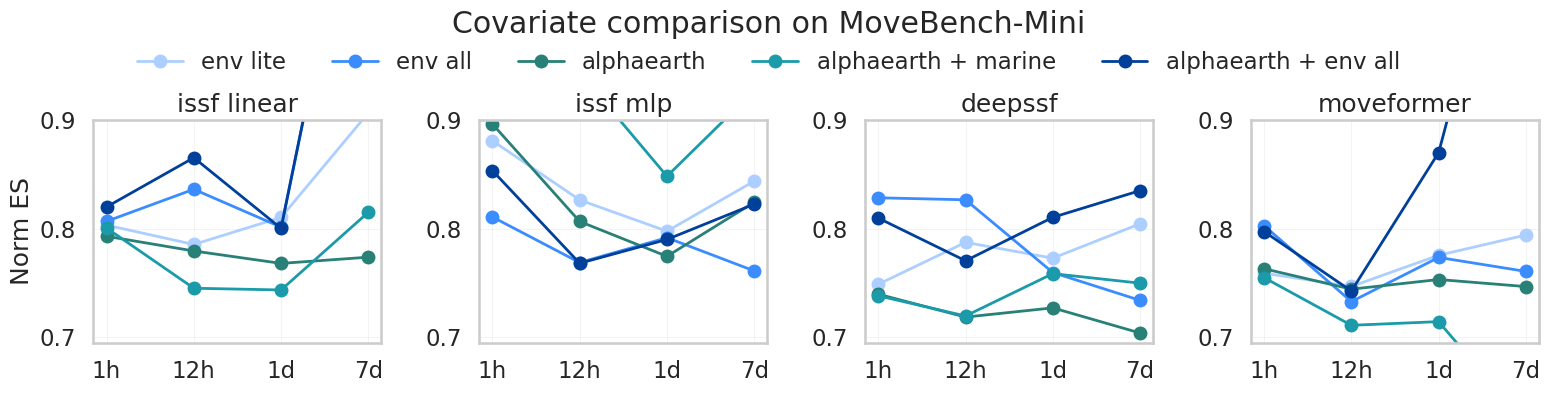

In [9]:
fig, axes = plt.subplots(1, len(COVARIATE_COMPARISON_METHODS), figsize=(16, 4), sharex=True)

for col, method in enumerate(COVARIATE_COMPARISON_METHODS):
    ax = axes[col]
    method_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["method"] == method
    ].copy()

    for covariate_set in COVARIATE_SET_ORDER:
        covariate_rows = method_subset[method_subset["covariate_set"] == covariate_set].sort_values("x")
        if covariate_rows.empty:
            continue
        ax.plot(
            covariate_rows["x"],
            covariate_rows["mean_value"],
            marker="o",
            linewidth=2.0,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
        )

    ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
    ax.set_ylim(0.695, 0.9)
    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_title(_method_label(method))

axes[0].set_ylabel("Norm ES")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(COVARIATE_SET_ORDER) + 1,
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
)
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.0)
fig.tight_layout()

plt.savefig("cov-1.pdf", bbox_inches="tight", dpi=300)


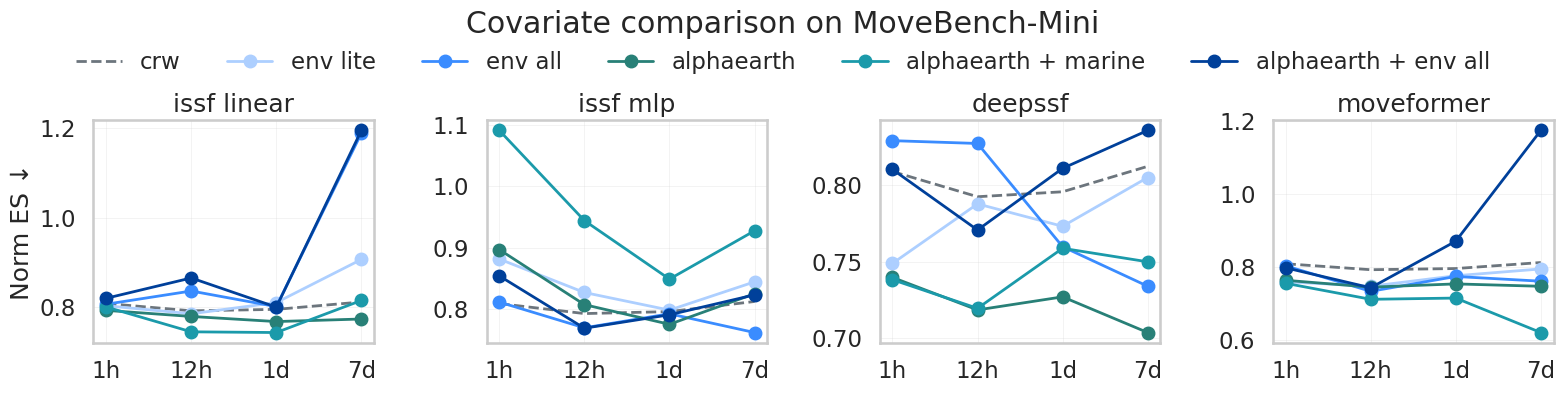

In [10]:
fig, axes = plt.subplots(1, len(COVARIATE_COMPARISON_METHODS), figsize=(16, 4), sharex=True)

for col, method in enumerate(COVARIATE_COMPARISON_METHODS):
    ax = axes[col]
    method_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["method"] == method
    ].copy()

    if not randomwalk_collapsed_df.empty:
        ax.plot(
            randomwalk_collapsed_df["x"],
            randomwalk_collapsed_df["mean_value"],
            marker=None,
            linewidth=2.0,
            linestyle="--",
            color="#6c757d",
            label="crw",
        )

    for covariate_set in COVARIATE_SET_ORDER:
        covariate_rows = method_subset[method_subset["covariate_set"] == covariate_set].sort_values("x")
        if covariate_rows.empty:
            continue
        ax.plot(
            covariate_rows["x"],
            covariate_rows["mean_value"],
            marker="o",
            linewidth=2.0,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
        )

    ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
    # ax.set_ylim(0.695, 0.9)
    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_title(_method_label(method))

axes[0].set_ylabel("Norm ES ↓")

handles, labels = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(COVARIATE_SET_ORDER) + 1,
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
)
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.0)
fig.tight_layout()

plt.savefig("cov-1-withrw.pdf", bbox_inches="tight", dpi=300)
plt.savefig("cov-1-withrw.png", bbox_inches="tight", dpi=300)


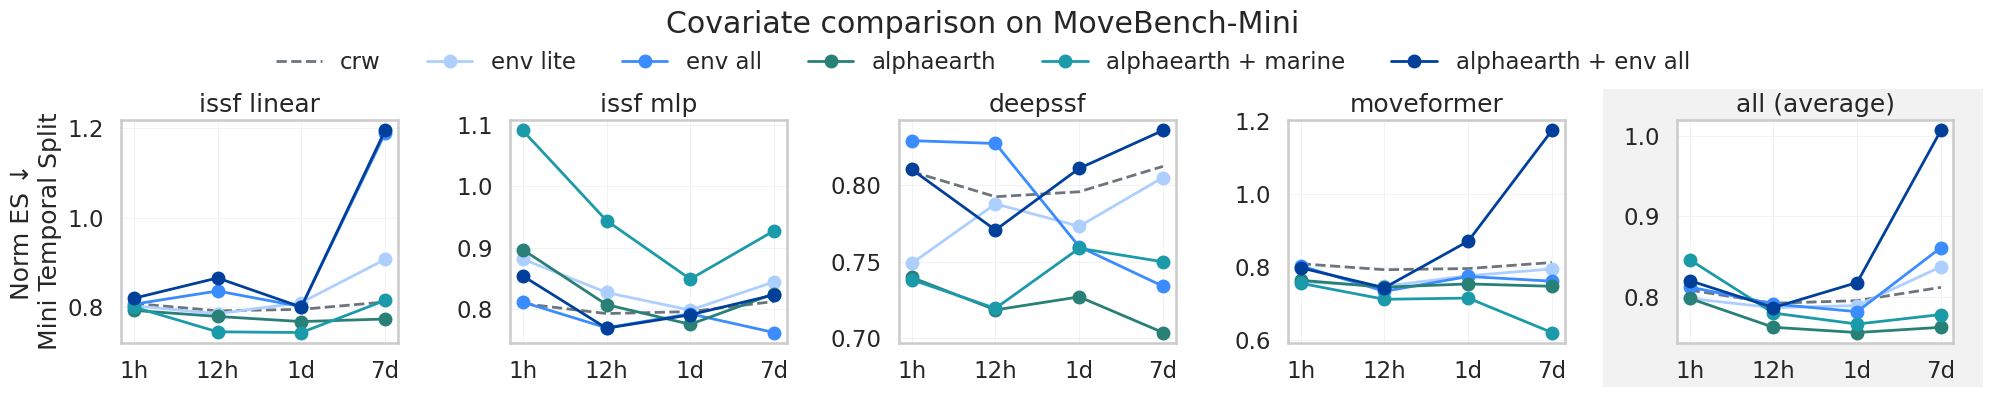

In [11]:
SHOW_LITE = True
SHOW_ALL_ENVIRONMENTAL = True
SHOW_ALPHAEARTH_ONLY = True
SHOW_ALPHAEARTH_AND_MARINE = True
SHOW_ALL = True

selected_covariate_sets = [
    covariate_set
    for covariate_set, enabled in [
        ("lite", SHOW_LITE),
        ("all_environmental", SHOW_ALL_ENVIRONMENTAL),
        ("alphaearth_only", SHOW_ALPHAEARTH_ONLY),
        ("alphaearth_and_marine", SHOW_ALPHAEARTH_AND_MARINE),
        ("all", SHOW_ALL),
    ]
    if enabled
]


def _average_covariate_collapsed_df(collapsed_df: pd.DataFrame) -> pd.DataFrame:
    average_df = (
        collapsed_df[
            collapsed_df["method"].isin(COVARIATE_COMPARISON_METHODS)
        ]
        .groupby(["covariate_set", "timescale"], as_index=False)
        .agg(mean_value=("mean_value", "mean"))
    )
    average_df["x"] = average_df["timescale"].map(TIMESCALE_ORDER.index)
    return average_df


AVERAGE_PANEL_BACKGROUND_COLOR = "#f2f2f2"
AVERAGE_PANEL_BACKGROUND_PAD = 0.01

plot_methods = [*COVARIATE_COMPARISON_METHODS, "all_average"]
plot_titles = {
    **{method: _method_label(method) for method in COVARIATE_COMPARISON_METHODS},
    "all_average": "all (average)",
}

split_plot_rows = [
    (
        "Mini Temporal Split",
        covariate_collapsed_aggregate_df,
        randomwalk_collapsed_df,
    ),
    (
        "Mini Individual Split",
        individual_covariate_collapsed_aggregate_df,
        individual_randomwalk_collapsed_df,
    ),
]

fig, axes = plt.subplots(
    len(split_plot_rows),
    len(plot_methods),
    figsize=(4 * len(plot_methods), 4 * len(split_plot_rows)),
    sharex=True,
    squeeze=False,
)

for row, (split_label, collapsed_df, split_randomwalk_df) in enumerate(split_plot_rows):
    average_covariate_collapsed_df = _average_covariate_collapsed_df(collapsed_df)

    for col, method in enumerate(plot_methods):
        ax = axes[row, col]
        if method == "all_average":
            method_subset = average_covariate_collapsed_df.copy()
        else:
            method_subset = collapsed_df[collapsed_df["method"] == method].copy()

        if not split_randomwalk_df.empty:
            ax.plot(
                split_randomwalk_df["x"],
                split_randomwalk_df["mean_value"],
                marker=None,
                linewidth=2.0,
                linestyle="--",
                color="#6c757d",
                label="crw",
            )

        for covariate_set in selected_covariate_sets:
            covariate_rows = method_subset[method_subset["covariate_set"] == covariate_set].sort_values("x")
            if covariate_rows.empty:
                continue
            ax.plot(
                covariate_rows["x"],
                covariate_rows["mean_value"],
                marker="o",
                linewidth=2.0,
                color=COVARIATE_COLORS[covariate_set],
                label=_covariate_label(covariate_set),
            )

        ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
        ax.grid(True, linewidth=0.4, alpha=0.4)
        if row == 0:
            ax.set_title(plot_titles[method])

    axes[row, 0].set_ylabel(f"Norm ES ↓\n{split_label}")

handles, labels = [], []
for row_axes in axes:
    for ax in row_axes:
        h, l = ax.get_legend_handles_labels()
        for handle, label in zip(h, l):
            if label not in labels:
                handles.append(handle)
                labels.append(label)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=max(1, len(labels)),
    frameon=False,
    bbox_to_anchor=(0.5, 0.98),
)
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.01)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.canvas.draw()

for average_ax in axes[:, -1]:
    average_ax.set_facecolor("white")
average_bboxes = [
    ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.transFigure.inverted())
    for ax in axes[:, -1]
]
background_left = max(0.0, min(bbox.x0 for bbox in average_bboxes) - AVERAGE_PANEL_BACKGROUND_PAD)
background_bottom = max(0.0, min(bbox.y0 for bbox in average_bboxes) - AVERAGE_PANEL_BACKGROUND_PAD)
background_right = 1.0
background_top = min(1.0, max(bbox.y1 for bbox in average_bboxes) + AVERAGE_PANEL_BACKGROUND_PAD)
average_background_ax = fig.add_axes(
    [
        background_left,
        background_bottom,
        background_right - background_left,
        background_top - background_bottom,
    ],
    zorder=0,
)
average_background_ax.set_facecolor(AVERAGE_PANEL_BACKGROUND_COLOR)
average_background_ax.set_xticks([])
average_background_ax.set_yticks([])
for spine in average_background_ax.spines.values():
    spine.set_visible(False)
average_background_ax.set_in_layout(False)
for row_axes in axes:
    for ax in row_axes:
        ax.set_zorder(1)

plt.savefig("cov-1-withrw-average.pdf", bbox_inches="tight", dpi=300)
plt.savefig("cov-1-withrw-average.png", bbox_inches="tight", dpi=300)


In [12]:
covariate_counts_df = (
    core_covariate_normalized_energy_df.groupby(["method", "covariate_set"], as_index=False)
    .agg(
        n_experiments_shown=("value", "size"),
        n_studies=("study_id", "nunique"),
        n_timescales=("timescale", "nunique"),
        timescales_shown=(
            "timescale",
            lambda values: ", ".join(sorted(pd.unique(values), key=TIMESCALE_ORDER.index)),
        ),
    )
)

covariate_counts_df = (
    pd.MultiIndex.from_product(
        [COVARIATE_COMPARISON_METHODS, COVARIATE_SET_ORDER],
        names=["method", "covariate_set"],
    )
    .to_frame(index=False)
    .merge(covariate_counts_df, on=["method", "covariate_set"], how="left")
)

for column in ["n_experiments_shown", "n_studies", "n_timescales"]:
    covariate_counts_df[column] = covariate_counts_df[column].fillna(0).astype(int)
covariate_counts_df["timescales_shown"] = covariate_counts_df["timescales_shown"].fillna("")
covariate_counts_df["method_label"] = covariate_counts_df["method"].map(_method_label)
covariate_counts_df["covariate_label"] = covariate_counts_df["covariate_set"].map(_covariate_label)

covariate_counts_df[
    [
        "method_label",
        "covariate_label",
        "n_experiments_shown",
        "n_studies",
        "n_timescales",
        "timescales_shown",
    ]
].sort_values(["method_label", "covariate_label"]).reset_index(drop=True)


,method_label,covariate_label,n_experiments_shown,n_studies,n_timescales,timescales_shown
0,deepssf,alphaearth,38,10,4,"1h, 12h, 1d, 7d"
1,deepssf,alphaearth + env all,34,10,4,"1h, 12h, 1d, 7d"
2,deepssf,alphaearth + marine,38,10,4,"1h, 12h, 1d, 7d"
3,deepssf,env all,37,10,4,"1h, 12h, 1d, 7d"
4,deepssf,env lite,38,10,4,"1h, 12h, 1d, 7d"
5,issf linear,alphaearth,38,10,4,"1h, 12h, 1d, 7d"
6,issf linear,alphaearth + env all,38,10,4,"1h, 12h, 1d, 7d"
7,issf linear,alphaearth + marine,12,3,4,"1h, 12h, 1d, 7d"
8,issf linear,env all,38,10,4,"1h, 12h, 1d, 7d"
9,issf linear,env lite,38,10,4,"1h, 12h, 1d, 7d"
